In [1]:
#Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from lmfit.models import GaussianModel, VoigtModel, ConstantModel
from scipy.special import wofz
from pathlib import Path
from scipy.ndimage import median_filter
from scipy.signal import find_peaks

<h3 style="color: #e19edc;"> Lectura de espectros</h3>

<h5 style="color: #e19edc;"> 2026</h5>

In [5]:
ruta_8_abril = r"C:\Users\Jessi Dani\OneDrive - Universidad de los andes\TESIS\Tesis\Datos ESPARTACO\Espectro de Unicornio\Unicornio 8 abril de 2026.xlsx"

In [6]:
unicornio_8_abril = pd.read_excel(ruta_8_abril, sheet_name= "Sheet1", usecols = [1,2],header = None, names = ["Longitud onda", "Flujo"])

In [7]:
espectros = {
    "unicornio_8_abril": unicornio_8_abril
}

<h4 style="color: #e19edc;"> Parámetros de la normalización con el método Sigma - Clipping</h4>

In [12]:
guardar_graficos = True   
carpeta_graficos = "./Graficas Unicornio/Espectros normalizados"  
 
col_longitud_onda = "Longitud onda"
col_flujo = "Flujo"
col_flujo_norm = "Flujo Normalizado"
 
grado_polinomio= 2     
N_iteraciones = 10
sigma_corte = 2.0

In [13]:
def ajustar_continuo(longitud_onda, flujo, grado, n_iter, sigma):

    longitud_onda = np.asarray(longitud_onda, dtype=float)
    flujo = np.asarray(flujo, dtype=float)
 
    mascara = np.ones_like(flujo, dtype=bool)
 
    for _ in range(n_iter):
        coef = np.polyfit(longitud_onda[mascara], flujo[mascara], deg=grado)
        continuo_iter = np.polyval(coef, longitud_onda)
 
        residuo = flujo - continuo_iter
        
        mediana = np.median(residuo[mascara])
        mad = np.median(np.abs(residuo[mascara] - mediana))
        mad_std = mad * 1.4826

        umbral_superior = mediana + sigma * mad_std
        umbral_inferior = mediana - sigma * mad_std
        nueva_mascara = (residuo > umbral_inferior) & (residuo < umbral_superior)
 
        if nueva_mascara.sum() < grado + 2:
            break

        if np.array_equal(nueva_mascara, mascara):
            break
 
        mascara = nueva_mascara
 
    coef_final = np.polyfit(longitud_onda[mascara], flujo[mascara], deg=grado)
    continuo = np.polyval(coef_final, longitud_onda)
 
    return continuo, mascara


Procesando: unicornio_8_abril
  Puntos totales: 59
  Puntos excluidos: 23
  -> Gráfico guardado: Graficas Unicornio\Espectros normalizados\unicornio_8_abril_control.png


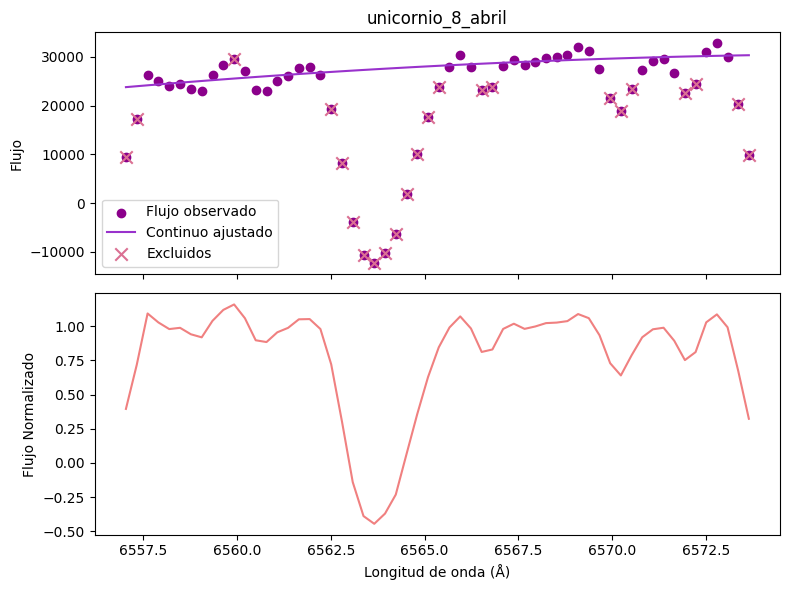


Proceso completo.


In [15]:
if guardar_graficos:
    Path(carpeta_graficos).mkdir(exist_ok=True)
 
for nombre, df in espectros.items():
    print(f"\nProcesando: {nombre}")
 
    longitud_onda = df[col_longitud_onda].values

    #if nombre in espectros_normalizados:
        
        #print("  Espectro ya normalizado: se omite el ajuste del continuo.")

        
        #if col_flujo_norm not in df.columns:

            #df[col_flujo_norm] = df[col_flujo]

        #flujo_norm = df[col_flujo_norm].values

        #fig, ax = plt.subplots(figsize=(8, 4))

        #ax.plot(longitud_onda, flujo_norm, color="lightcoral")

        #ax.axhline(1, color="gray", ls="--", lw=0.8)

        #ax.set_ylabel("Flujo Normalizado")

        #ax.set_xlabel("Longitud de onda (Å)")
        
        #ax.set_title(f"{nombre} (Ya está normalizado desde la fuente de datos)")

    #else:
    
    flujo = df[col_flujo].values

    continuo, mascara_continuo = ajustar_continuo(longitud_onda, flujo, grado_polinomio, N_iteraciones, sigma_corte)

    df["Continuo ajustado"] = continuo
    df["Flujo Normalizado"] = flujo / continuo
    df["Usado en ajuste"] = mascara_continuo

    print(f"  Puntos totales: {len(mascara_continuo)}")
    print(f"  Puntos excluidos: {(~mascara_continuo).sum()}")

    mascara_bool = np.asarray(mascara_continuo, dtype=bool)

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

    ax1.scatter(longitud_onda, flujo, color = "darkmagenta", label="Flujo observado")
    ax1.plot(longitud_onda, continuo, color ="darkorchid", label="Continuo ajustado")
    ax1.scatter(longitud_onda[~mascara_bool], flujo[~mascara_bool], color = "palevioletred",marker = "x", label="Excluidos", s = 80)
    ax1.set_ylabel("Flujo")
    ax1.legend()
    ax1.set_title(nombre)

    ax2.plot(longitud_onda, df["Flujo Normalizado"], color ="lightcoral")
    ax2.set_ylabel("Flujo Normalizado")
    ax2.set_xlabel("Longitud de onda (Å)")
 
    plt.tight_layout()
 
    if guardar_graficos:
        fig_path = Path(carpeta_graficos) / f"{nombre}_control.png"
        plt.savefig(fig_path, dpi=120)
        print(f"  -> Gráfico guardado: {fig_path}")
 
    plt.show()
    plt.close(fig)
 
print("\nProceso completo.")

In [52]:
metadatos = {
    "unicornio_8_abril": {
        "fecha": "Abril 08-2026",
        "datos": unicornio_8_abril,
        "ventana_vecinos": 4,
        "centro_aprox": 6563.661,
        "Velocidad": 44.86, #km/s
        "Incertidumbre v": 0.65, #km/s
    }
}

<h3 style="color: #e19edc;"> Obtención del perfil de absorción y emisión de la línea H<sub>&alpha;</sub></h3>

<h4 style="color: #e19edc;"> Teniendo en cuenta las posibles mezclas con las líneas de absorción</h4>

In [18]:
c_kms_s = 299792.458

def efecto_doppler(longitud_lab, velocidad_kms):
    return longitud_lab * (1 + velocidad_kms / c_kms_s)

def profundidad_interpolada(teff, t_ref=(3500, 4250), prof_ref=(0.55, 0.63)):
    return float(np.interp(teff, t_ref, prof_ref))

def pico_unitario_voigt(sigma, gamma):
    z = 1j * gamma / (sigma * np.sqrt(2))
    return wofz(z).real / (sigma * np.sqrt(2 * np.pi))

In [ ]:
def estimar_continuo_por_planitud(longitud_onda, flujo, rango_flujo=(0.8, 1.1), factor_ruido=0.7, ventana_vecinos=2,
                                  grado_ajuste=2, min_puntos=5, excluir=None):
    
    longitud_onda = np.asarray(longitud_onda)
    flujo = np.asarray(flujo)

    # 1) Ruido estimado de forma robusta (MAD)
    dif = np.diff(flujo)
    sigma_ruido = 1.4826 * np.median(np.abs(dif - np.median(dif))) / np.sqrt(2)

    # 2) Variación local
    ventana_total = 2 * ventana_vecinos + 1
    variacion_local = (pd.Series(flujo)
                       .rolling(window=ventana_total, center=True, min_periods=2)
                       .std().to_numpy())

    # 3) Umbral proporcional al ruido
    max_variacion = factor_ruido * sigma_ruido

    mascara_rango = (flujo >= rango_flujo[0]) & (flujo <= rango_flujo[1])
    mascara_plano = variacion_local < max_variacion
    mascara = mascara_rango & mascara_plano

    # 4) Zonas de líneas excluidas a mano
    if excluir:
        for lo, hi in excluir:
            mascara &= ~((longitud_onda >= lo) & (longitud_onda <= hi))

    x_sel, y_sel = longitud_onda[mascara], flujo[mascara]

    print(f"sigma_ruido={sigma_ruido:.3f}, umbral={max_variacion:.3f}, "
          f"puntos que pasan: rango={mascara_rango.sum()}, "
          f"plano={mascara_plano.sum()}, final={mascara.sum()}")

    if x_sel.size < min_puntos:
        raise ValueError(
            f"Solo {x_sel.size} puntos (mínimo {min_puntos}). "
            f"sigma_ruido={sigma_ruido:.3f}, umbral={max_variacion:.3f}. "
            f"Sube factor_ruido o relaja rango_flujo."
        )

    orden = np.argsort(x_sel)
    x_sel, y_sel = x_sel[orden], y_sel[orden]

    continuo_func = np.poly1d(np.polyfit(x_sel, y_sel, deg=grado_ajuste))
    return continuo_func, x_sel, y_sel

sigma_ruido=0.096, umbral=0.096, puntos que pasan: rango=39, plano=14, final=14


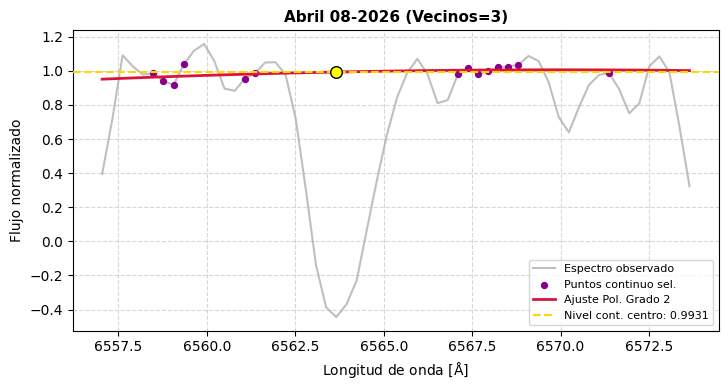

,Espectro / Fecha,Vecinos (G1),Continuo Centro (G1),Residuo std (G1)
0,Abril 08-2026,3,0.9931,0.02986


In [ ]:
# Configuración manual de vecinos por prueba específica

vecinos_manuales = {
    "Abril 08-2026": {"v_g1": 3},
}

filas_comparativa = []

n_columnas = 2
max_filas = 4
tam_bloque = n_columnas * max_filas

lista_metadatos = list(metadatos.values())

n_bloques = int(np.ceil(len(lista_metadatos) / tam_bloque))

for bloque_idx in range(n_bloques):

    bloque = lista_metadatos[bloque_idx * tam_bloque: (bloque_idx + 1) * tam_bloque]
    n_graficas = len(bloque)
    n_filas_bloque = int(np.ceil(n_graficas / n_columnas))

    fig, axes = plt.subplots(
        n_filas_bloque,
        n_columnas,
        figsize=(14, 4 * n_filas_bloque)
    )

    axes = np.array(axes).flatten()

    for i, archivo in enumerate(bloque):

        fecha = archivo["fecha"]
        df = archivo["datos"]
        centro_aprox = archivo["centro_aprox"]

        longitud_onda = df["Longitud onda"].values
        flujo = df["Flujo Normalizado"].values

        # Extraer ventana manual

        cfg = vecinos_manuales.get(fecha, {"v_g1": 4})
        v_g1 = cfg["v_g1"]

        # Grado 2

        try:
            cont_func1, x_sel1, y_sel1 = estimar_continuo_por_planitud(
                longitud_onda, flujo,
                rango_flujo=(0.8, 1.1),
                factor_ruido=1.0,
                ventana_vecinos=v_g1,
                grado_ajuste=2,
                excluir=[(6562.0, 6565.5)]   # núcleo de Hα
            )

            res1 = y_sel1 - cont_func1(x_sel1)
            c_centro1 = round(float(cont_func1(centro_aprox)), 4)
            std1 = round(float(np.std(res1)), 5)

        except Exception as e:
            print(f"[{fecha}] Falló el ajuste: {e}")
            cont_func1 = None
            c_centro1, std1 = None, f"Falló: {e}"

        # Tabla de resultados

        filas_comparativa.append({
            "Espectro / Fecha": fecha,
            "Vecinos (G1)": v_g1,
            "Continuo Centro (G1)": c_centro1,
            "Residuo std (G1)": std1
        })

        # Selección de Subplot con base en el índice (dentro del bloque)

        ax = axes[i]

        # Espectro observado
        ax.plot(longitud_onda, flujo, color="gray", alpha=0.5, label="Espectro observado", zorder=1)

        if cont_func1 is not None:

            # Continuo
            ax.scatter(x_sel1, y_sel1, color="darkmagenta", s=18, label="Puntos continuo sel.", zorder=2)

            # Ajuste polinómico
            ax.plot(longitud_onda, cont_func1(longitud_onda), color="crimson", lw=2, label="Ajuste Pol. Grado 2",
                     zorder=3)

            # Continuo evaluado en Hα
            ax.axhline(c_centro1, color="gold", linestyle="--", lw=1.5,
                       label=f"Nivel cont. centro: {c_centro1:.4f}", zorder=3)

            # Punto del centro aproximado
            ax.scatter([centro_aprox], [c_centro1], color="yellow", edgecolor="black", s=70, zorder=4)

        # Configuración del subplot

        ax.set_title(f"{fecha} (Vecinos={v_g1})", fontsize=11, fontweight="bold")
        ax.set_xlabel(r"Longitud de onda [$\mathrm{\AA}$]")
        ax.set_ylabel("Flujo normalizado")
        ax.legend(fontsize=8, loc="lower right")
        ax.grid(True, linestyle="--", alpha=0.5)

    # Eliminación de subplots vacíos si el número de espectros del bloque es impar

    for j in range(n_graficas, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()

    sufijo = f"_parte{bloque_idx + 1}" if n_bloques > 1 else ""

    plt.savefig(fr"Graficas Unicornio\Continuo\Continuo {sufijo}.png",
                dpi=300, bbox_inches="tight")

    plt.show()

tabla_comparativa_manual = pd.DataFrame(filas_comparativa)

display(tabla_comparativa_manual)